# Praktikum Data Science
## Nama: Muhammad Arif Hermawan Nim: 123240063 Kelas: IF-A

## Clustering: K-Means dan Hierarchical Clustering

**Studi Kasus:** Segmentasi Pelanggan Distributor Grosir  
**Dataset:** Wholesale Customers Dataset – Kaggle

**Link Dataset:**  
https://www.kaggle.com/datasets/binovi/wholesale-customers-data-set

### Tujuan
Menerapkan K-Means dan Hierarchical Clustering pada dataset yang sama, mengevaluasi hasil clustering, serta membandingkan karakteristik cluster yang dihasilkan oleh kedua metode.

### Ketentuan
- Kerjakan secara mandiri.
- Gunakan dataset dan hasil preprocessing yang sama untuk K-Means dan Hierarchical Clustering.
- `Channel` dan `Region` tidak digunakan sebagai fitur clustering.
- Berikan interpretasi pada setiap hasil utama.


## 1. Import Library

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from scipy.spatial.distance import pdist
from sklearn.metrics import silhouette_score

## 2. Load Dataset

Muat dataset Wholesale Customers ke dalam DataFrame.

**Tugas:**
- Baca dataset.
- Tampilkan 5 baris pertama.
- Tampilkan informasi umum dataset.


In [3]:
df = pd.read_csv('Wholesale customers data.csv')
display(df.head())
print(df.info())
display(df.describe())

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB
None


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


## 3. Exploratory Data Analysis (EDA)

Lakukan pemeriksaan awal terhadap dataset.

**Minimal lakukan:**
- ukuran dataset;
- tipe data;
- missing value;
- data duplikat;
- statistik deskriptif;
- distribusi fitur numerik yang relevan.


### 3.1. Ukuran Dataset

In [4]:
print("Jumlah baris", df.shape[0])
print("Jumlah kolom", df.shape[1])

Jumlah baris 440
Jumlah kolom 8


### 3.2 Tipe Data

In [5]:
print(df.dtypes)

Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object


### 3.3 Missing Value

In [6]:
print("Kolom dengan missing value:\n", df.isna().sum(), sep='')
print("\nKolom dengan nilai negatif:\n", (df <= 0).sum(), sep='')

Kolom dengan missing value:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Kolom dengan nilai negatif:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


### 3.4 Data Duplikat

In [7]:
print("Jumlah data duplikat:\n", df.duplicated().sum(), sep='')

Jumlah data duplikat:
0


### 3.5 Statistik Deskriptif

In [8]:
display(df.describe())

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


### 3.6 Analisis Univariate
Analaisis setiap fitur

In [9]:
print("Frekuensi data berdasarkan Channel:\n", df['Channel'].value_counts(), sep='')
print("\nFrekuensi data berdasarkan Region:\n", df['Region'].value_counts(), sep='')
display(df[['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']].describe())

Frekuensi data berdasarkan Channel:
Channel
1    298
2    142
Name: count, dtype: int64

Frekuensi data berdasarkan Region:
Region
3    316
1     77
2     47
Name: count, dtype: int64


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


### 3.7 Analisis Bivariate
analisis hubungan antar fitur

In [10]:
groupped_by_channel = df.groupby('Channel')[['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']].agg(['mean', 'median', 'std', 'min', 'max'])
groupped_by_region = df.groupby('Region')[['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']].agg(['mean', 'median', 'std', 'min', 'max'])

groupped_by_channel_and_region = df.groupby(['Channel', 'Region'])[['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']].agg(['mean', 'median', 'std', 'min', 'max'])

with pd.option_context('display.max_columns', None):
    display(groupped_by_channel)
    display(groupped_by_region)
    display(groupped_by_channel_and_region)

Fresh                                            Milk          \
                 mean  median           std min     max          mean  median   
Channel                                                                         
1        13475.560403  9581.5  13831.687502   3  112151   3451.724832  2157.0   
2         8904.323944  5993.5   8987.714750  18   44466  10716.500000  7812.0   

                                       Grocery                               \
                 std  min    max          mean   median           std   min   
Channel                                                                       
1        4352.165571   55  43950   3962.137584   2684.0   3545.513391     3   
2        9679.631351  928  73498  16322.852113  12390.0  12267.318094  2743   

                     Frozen                                 Detergents_Paper  \
           max         mean  median          std min    max             mean   
Channel                                                                        
1        21042  3748.251678  2057.5  5643.912500  25  60869       790.560403   
2        92780  1652.612676  1081.0  1812.803662  33  11559      7269.507042   

                                           Delicassen                       \
         median          std  min    max         mean  median          std   
Channel                                                                      
1         385.5  1104.093673    3   6907  1415.956376   821.0  3147.426922   
2        5614.5  6291.089697  332  40827  1753.436620  1350.0  1953.797047   

                    
        min    max  
Channel             
1         3  47943  
2         3  16523

Fresh                                           Milk          \
                mean  median           std min     max         mean  median   
Region                                                                        
1       11101.727273  7363.0  11557.438575  18   56083  5486.415584  3748.0   
2        9887.680851  8090.0   8387.899211   3   32717  5088.170213  2374.0   
3       12533.471519  8752.5  13389.213115   3  112151  5977.085443  3684.5   

                                     Grocery                              \
                std  min    max         mean  median           std   min   
Region                                                                     
1       5704.856079  258  28326  7403.077922  3838.0   8496.287728   489   
2       5826.343145  333  25071  9218.595745  6114.0  10842.745314  1330   
3       7935.463443   55  73498  7896.363924  4732.0   9537.287778     3   

                    Frozen                                  Detergents_Paper  \
          max         mean  median          std  min    max             mean   
Region                                                                         
1       39694  3000.337662  1801.0  3092.143894   61  18711      2651.116883   
2       67298  4045.361702  1455.0  9151.784954  131  60869      3687.468085   
3       92780  2944.594937  1498.0  4260.126243   25  36534      2817.753165   

                                        Delicassen                          \
       median          std min    max         mean median          std min   
Region                                                                       
1       737.0  4208.462708   5  19410  1354.896104  806.0  1345.423340   7   
2       811.0  6514.717668  15  38102  1159.702128  898.0  1050.739841  51   
3       856.0  4593.051613   3  40827  1620.601266  994.0  3232.581660   3   

               
          max  
Region         
1        6854  
2        5609  
3       47943

Fresh                                             Milk  \
                        mean  median           std  min     max          mean   
Channel Region                                                                  
1       1       12902.254237  8656.0  12342.008901  514   56083   3870.203390   
        2       11650.535714  9787.0   8969.362752    3   32717   2304.250000   
        3       13878.052133  9612.0  14746.572913    3  112151   3486.981043   
2       1        5200.000000  2926.0   5415.521495   18   20782  10784.000000   
        2        7289.789474  6468.0   6867.934548  161   27082   9190.789474   
        3        9831.504762  7362.0   9635.394129   23   44466  10981.009524   

                                                        Grocery           \
                median           std   min    max          mean   median   
Channel Region                                                             
1       1       2280.0   4298.321195   258  23527   4026.135593   2576.0   
        2       1560.5   2968.628697   333  16784   4395.500000   3352.0   
        3       2247.0   4508.505269    55  43950   3886.734597   2642.0   
2       1       8866.0   6609.221463  2527  28326  18471.944444  16106.0   
        2       6817.0   6611.354136   928  25071  16326.315789  12469.0   
        3       7845.0  10574.827178  1124  73498  15953.809524  12121.0   

                                                Frozen                        \
                         std   min    max         mean  median           std   
Channel Region                                                                 
1       1        3629.644143   489  16966  3127.322034  1859.0   3276.460124   
        2        3048.298815  1330  13626  5745.035714  2696.5  11454.478518   
        3        3593.506056     3  21042  3656.900474  1960.0   4956.590848   
2       1       10414.687844  5265  39694  2584.111111  1522.0   2424.774577   
        2       14035.453775  2743  67298  1540.578947   934.0   2473.266471   
        3       12298.935356  4523  92780  1513.200000  1059.0   1504.498737   

                           Detergents_Paper                                   \
                min    max             mean  median          std  min    max   
Channel Region                                                                 
1       1        91  18711       950.525424   412.0  1305.907616    5   5828   
        2       264  60869       482.714286   325.0   425.310506   15   1679   
        3        25  36534       786.682464   375.0  1099.970640    3   6907   
2       1        61   8321      8225.277778  6177.0  5515.878798  788  19410   
        2       131  11559      8410.263158  6236.0  8286.748255  332  38102   
        3        33   8132      6899.238095  5121.0  6022.091110  523  40827   

                 Delicassen                                   
                       mean  median          std  min    max  
Channel Region                                                
1       1       1197.152542   749.0  1219.945304    7   6854  
        2       1105.892857   883.0  1056.778800   51   5609  
        3       1518.284360   823.0  3663.183304    3  47943  
2       1       1871.944444  1414.0  1626.486667  120   6372  
        2       1239.000000  1037.0  1065.438042   59   3508  
        3       1826.209524  1386.0  2119.052222    3  16523

### 3.8 Analisis Korelasi

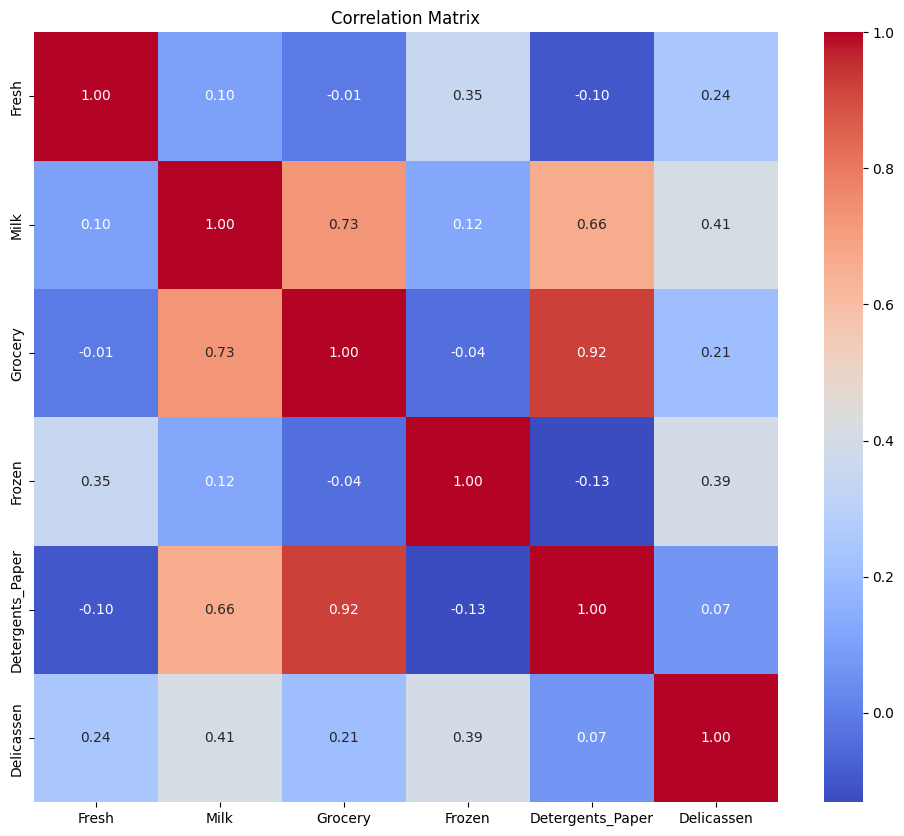

In [11]:
continuous_correlation_matrix = df[['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(continuous_correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

### 3.9 Check Skewness dan Outlier
Dataset yang digunakan memiliki distribusi yang tidak simetris, dibuktikan dengan nilai skewness yang tinggi, sehingga perlu dilakukan transformasi data. Selain itu, dataset juga memiliki outlier yang perlu ditangani.

Skewness of continuous features:
Fresh                2.561323
Milk                 4.053755
Grocery              3.587429
Frozen               5.907986
Detergents_Paper     3.631851
Delicassen          11.151586
dtype: float64


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.00,440.00,440.00,440.00,440.00,440.00
mean,12000.30,5796.27,7951.28,3071.93,2881.49,1524.87
std,12647.33,7380.38,9503.16,4854.67,4767.85,2820.11
min,3.00,55.00,3.00,25.00,3.00,3.00
25%,3127.75,1533.00,2153.00,742.25,256.75,408.25
50%,8504.00,3627.00,4755.50,1526.00,816.50,965.50
75%,16933.75,7190.25,10655.75,3554.25,3922.00,1820.25
max,112151.00,73498.00,92780.00,60869.00,40827.00,47943.00
median,8504.00,3627.00,4755.50,1526.00,816.50,965.50
skewness,2.56,4.05,3.59,5.91,3.63,11.15


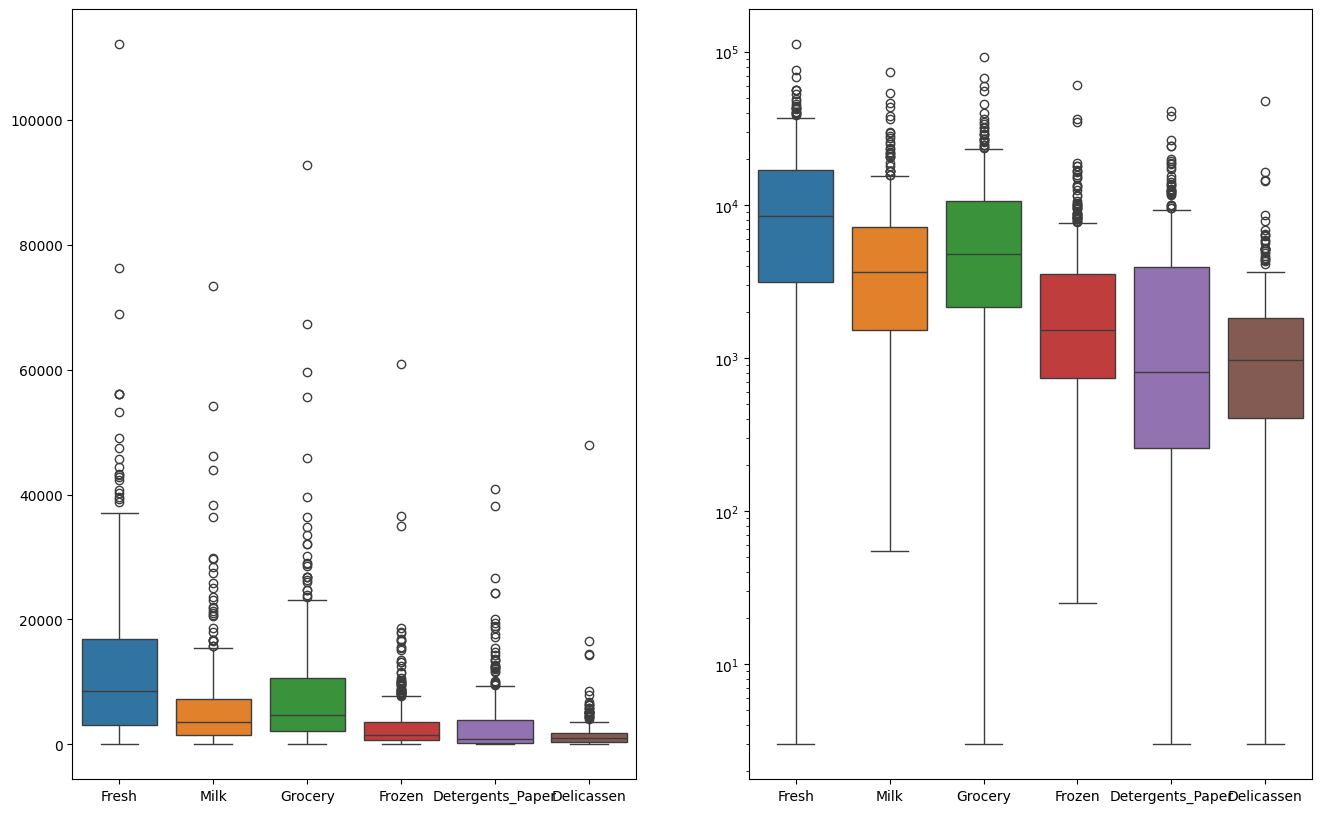

In [12]:
# Check skewness across continuous features
continuous_features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
print("Skewness of continuous features:")
print(df[continuous_features].skew())

desc = df[continuous_features].describe()
desc.loc['median'] = df[continuous_features].median()
desc.loc['skewness'] = df[continuous_features].skew()
desc.loc['mode'] = df[continuous_features].mode().iloc[0]

display(desc.round(2))

# Check for outliers using boxplots
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 10))
sns.boxplot(data=df[continuous_features], ax=axes[0])
axes[0].set_yscale('linear')
sns.boxplot(data=df[continuous_features], ax=axes[1])
axes[1].set_yscale('log')
plt.show()


## 4. Data Preprocessing

Lakukan preprocessing sesuai kondisi dataset.

**Periksa dan tangani jika diperlukan:**
- missing value;
- data duplikat/redundan;
- data yang tidak sesuai.

Kemudian tentukan fitur yang relevan untuk clustering.

> Jangan gunakan `Channel` dan `Region` sebagai fitur clustering.


Data relatif bersih, namun perlu dilakukan transformasi data untuk mengurangi skewness dan menangani outlier. Oleh karena itu Saya akan melakukan transformasi logaritmik pada fitur numerik dan menghapus outlier menggunakan metode transformasi logaritmik.

### 4.1 Transformasi Data

In [13]:
df_log = np.log1p(df[continuous_features])
display(df_log.head(10))



,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,9.446992,9.175438,8.930891,5.370638,7.891705,7.199678
1,8.861917,9.191259,9.166284,7.474772,8.099858,7.482682
2,8.756840,9.083529,8.947026,7.785721,8.165364,8.967632
3,9.492960,7.087574,8.348064,8.764834,6.230481,7.489412
4,10.026413,8.596189,8.881697,8.272826,7.483244,8.553718
5,9.149953,9.019180,8.542276,6.502790,7.493317,7.280697
6,9.403190,8.070906,8.850231,6.175867,8.052296,6.302619
7,8.933268,8.508556,9.151333,7.420579,8.108322,7.850493
8,8.693497,8.202208,8.731175,6.054439,7.448334,6.621406
9,8.700681,9.314160,9.845964,7.056175,8.912743,7.649216


Skewness of continuous features:
Fresh              -1.575326
Milk               -0.224063
Grocery            -0.674938
Frozen             -0.352655
Detergents_Paper   -0.235961
Delicassen         -1.091827
dtype: float64


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.00,440.00,440.00,440.00,440.00,440.00
mean,8.73,8.12,8.44,7.30,6.79,6.67
std,1.47,1.08,1.11,1.28,1.71,1.29
min,1.39,4.03,1.39,3.26,1.39,1.39
25%,8.05,7.34,7.68,6.61,5.55,6.01
50%,9.05,8.20,8.47,7.33,6.71,6.87
75%,9.74,8.88,9.27,8.18,8.27,7.51
max,11.63,11.21,11.44,11.02,10.62,10.78
median,9.05,8.20,8.47,7.33,6.71,6.87
skewness,-1.58,-0.22,-0.67,-0.35,-0.24,-1.09


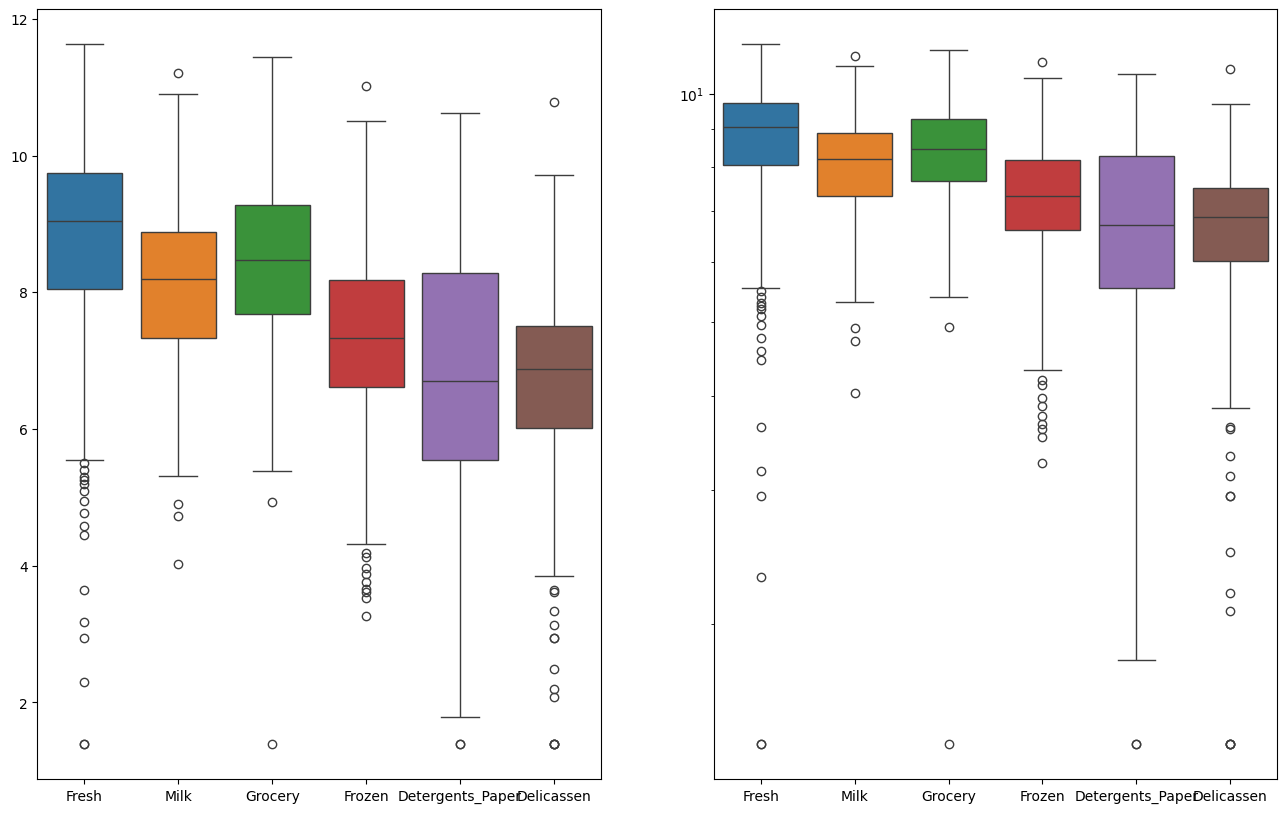

In [14]:
# Cek kembali skewness setelah transformasi logaritmik
print("Skewness of continuous features:")
print(df_log[continuous_features].skew())

desc = df_log[continuous_features].describe()
desc.loc['median'] = df_log[continuous_features].median()
desc.loc['skewness'] = df_log[continuous_features].skew()
desc.loc['mode'] = df_log[continuous_features].mode().iloc[0]

display(desc.round(2))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 10))
sns.boxplot(data=df_log[continuous_features], ax=axes[0])
axes[0].set_yscale('linear')
sns.boxplot(data=df_log[continuous_features], ax=axes[1])
axes[1].set_yscale('log')
plt.show()

## 5. Feature Selection

Tentukan fitur numerik yang digunakan untuk proses clustering.

**Tuliskan alasan singkat pemilihan fitur.**

Fitur yang dipilih adalah fitur numerik yang relevan untuk segmentasi pelanggan, seperti `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, dan `Delicassen`. Fitur-fitur ini mencerminkan pola pembelian pelanggan dan dapat membantu dalam mengidentifikasi kelompok pelanggan yang berbeda. Sementara fitur `Channel` dan `Region` tidak digunakan karena mereka bersifat kategorikal dan tidak relevan untuk proses clustering.


In [15]:
continuous_features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

X = df_log[continuous_features].copy()

## 6. Scaling

Lakukan standardisasi terhadap fitur yang telah dipilih.

> **Penting:** hasil scaling pada bagian ini akan digunakan kembali untuk **K-Means dan Hierarchical Clustering**. Jangan membuat preprocessing/scaling yang berbeda untuk kedua algoritma.


In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(
    X_scaled, 
    columns=continuous_features, 
    index=X.index
)

display(X_scaled_df.head(10))

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.486184,0.976299,0.440155,-1.509250,0.644143,0.408966
1,0.087889,0.990956,0.652171,0.134052,0.766043,0.627926
2,0.016356,0.891151,0.454687,0.376899,0.804405,1.776833
3,0.517477,-0.957973,-0.084792,1.141574,-0.328712,0.633133
4,0.880631,0.439662,0.395847,0.757322,0.404939,1.456588
5,0.283972,0.831535,0.090133,-0.625053,0.410837,0.471650
6,0.456365,-0.046979,0.367505,-0.880376,0.738190,-0.285090
7,0.136462,0.358475,0.638705,0.091728,0.771000,0.912502
8,-0.026765,0.074664,0.260272,-0.975210,0.384494,-0.038444
9,-0.021875,1.104815,1.264352,-0.192867,1.242089,0.756774


# A. K-MEANS CLUSTERING

## 7. Menentukan Jumlah Cluster dengan Elbow Method

Gunakan Elbow Method untuk membantu menentukan jumlah cluster yang sesuai.

**Output:**
- grafik Elbow Method;
- kandidat jumlah cluster;
- alasan singkat pemilihan jumlah cluster.


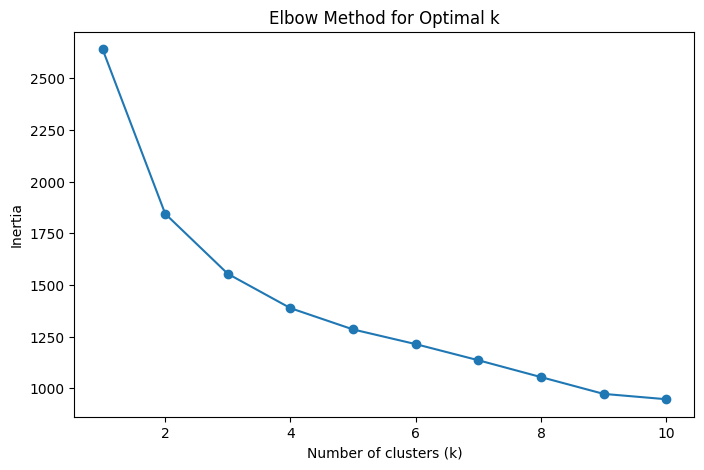

In [17]:
inertia = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled_df)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')
plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.show()

Cluster yang dipilih adalah 2 karena kurva mulai melandai dari titik tersebut, sudut kurva paling tajam terjadi di titk 2, kemudian dilanjutkan tren yang melandai relatif stabil, menunjukkan bahwa menambahkan lebih banyak cluster tidak mengurangi inertia secara signifikan.

## 8. Implementasi K-Means

Terapkan K-Means menggunakan jumlah cluster yang dipilih berdasarkan analisis sebelumnya.

**Output:**
- label cluster;
- jumlah anggota setiap cluster.


In [18]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X_scaled_df)
X_scaled_df['Cluster_KMeans'] = labels_kmeans
display(X_scaled_df.sample(10))

# jumlah anggota tiap cluster
cluster_summary = (
    X_scaled_df['Cluster_KMeans']
    .value_counts()
    .sort_index()
    .rename_axis('Cluster')
    .reset_index(name='Jumlah Anggota')
)
display(cluster_summary)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster_KMeans
35,-1.496019,0.453427,0.785199,-0.450547,0.913891,-0.457382,1
331,0.403688,1.376954,1.581111,-0.143937,1.392891,0.258954,1
430,-0.472653,0.211763,1.142022,-0.739611,-0.762978,0.750110,1
416,-0.235358,1.091950,0.770215,-0.436625,1.184369,0.178449,1
285,1.273141,-1.536573,-0.228089,-0.275900,-0.416876,-2.883317,0
437,0.579528,1.413991,1.688657,-0.953514,1.647619,0.666566,1
352,-1.580041,-1.030387,-0.996678,-0.453361,-1.335766,-1.077750,0
313,0.310285,-1.195788,-0.591289,0.856807,-0.923441,-0.753586,0
155,-0.773972,1.070535,1.291556,-1.443113,1.502177,0.776786,1
154,-1.564568,-3.794924,-3.165882,-2.321402,-2.759667,-3.461438,0


,Cluster,Jumlah Anggota
0,0,252
1,1,188


## 9. Evaluasi K-Means dengan Silhouette Score

Hitung Silhouette Score dari hasil K-Means.

**Tuliskan interpretasi singkat terhadap nilai yang diperoleh.**


In [19]:
silhoutte_avg = silhouette_score(X_scaled_df[continuous_features], labels_kmeans)
print(f"Silhouette Score for KMeans with 2 clusters: {silhoutte_avg:.4f}")

Silhouette Score for KMeans with 2 clusters: 0.2903


Nilai yang diperoleh dari silhoutte score yang secara teknis tergolong rendah memang sudah sewajanya bernilai seperti itu karena data bisnis tersebut memiliki karakteristik saling overlap, dimana banyak pelanggan menengah yang membeli berbagai jenis produk.

## 10. Visualisasi Hasil K-Means

Buat visualisasi yang sesuai untuk membantu melihat pembagian cluster.

Jika jumlah fitur lebih dari dua, pilih pendekatan visualisasi yang sesuai dengan materi praktikum.


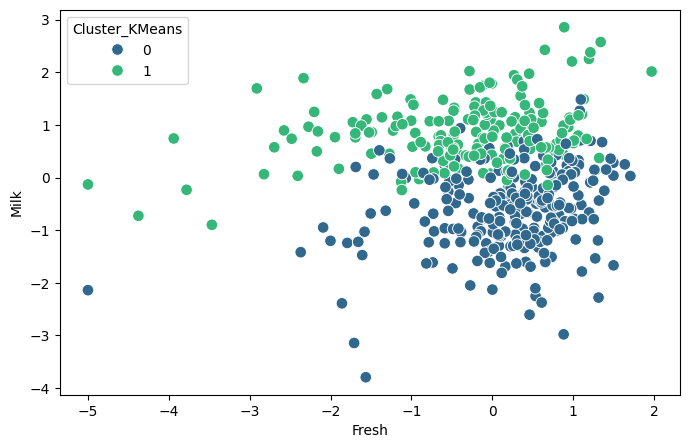

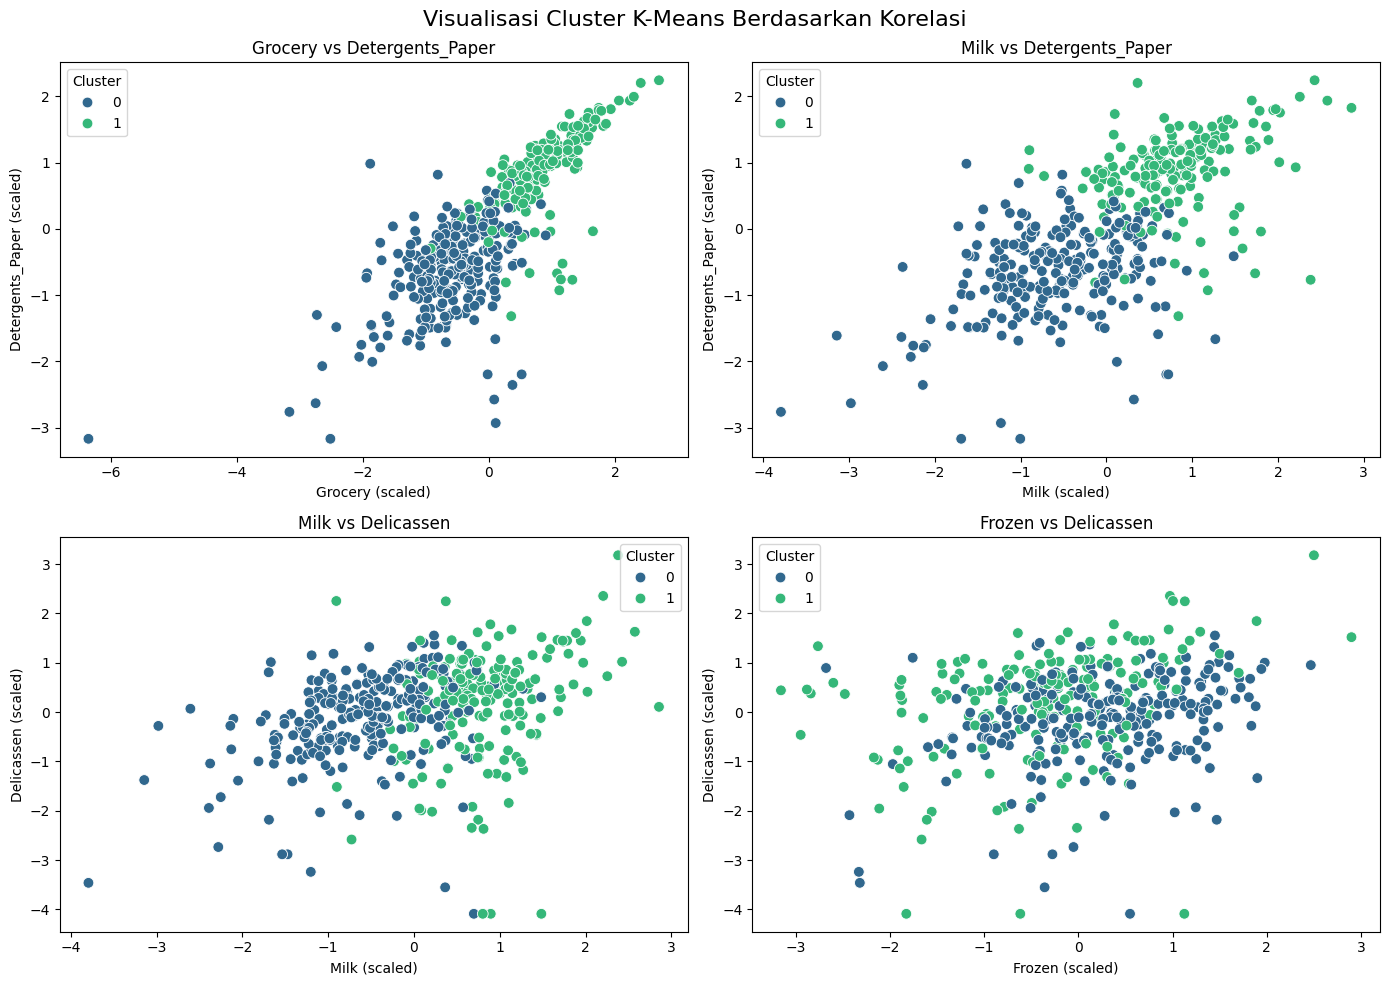

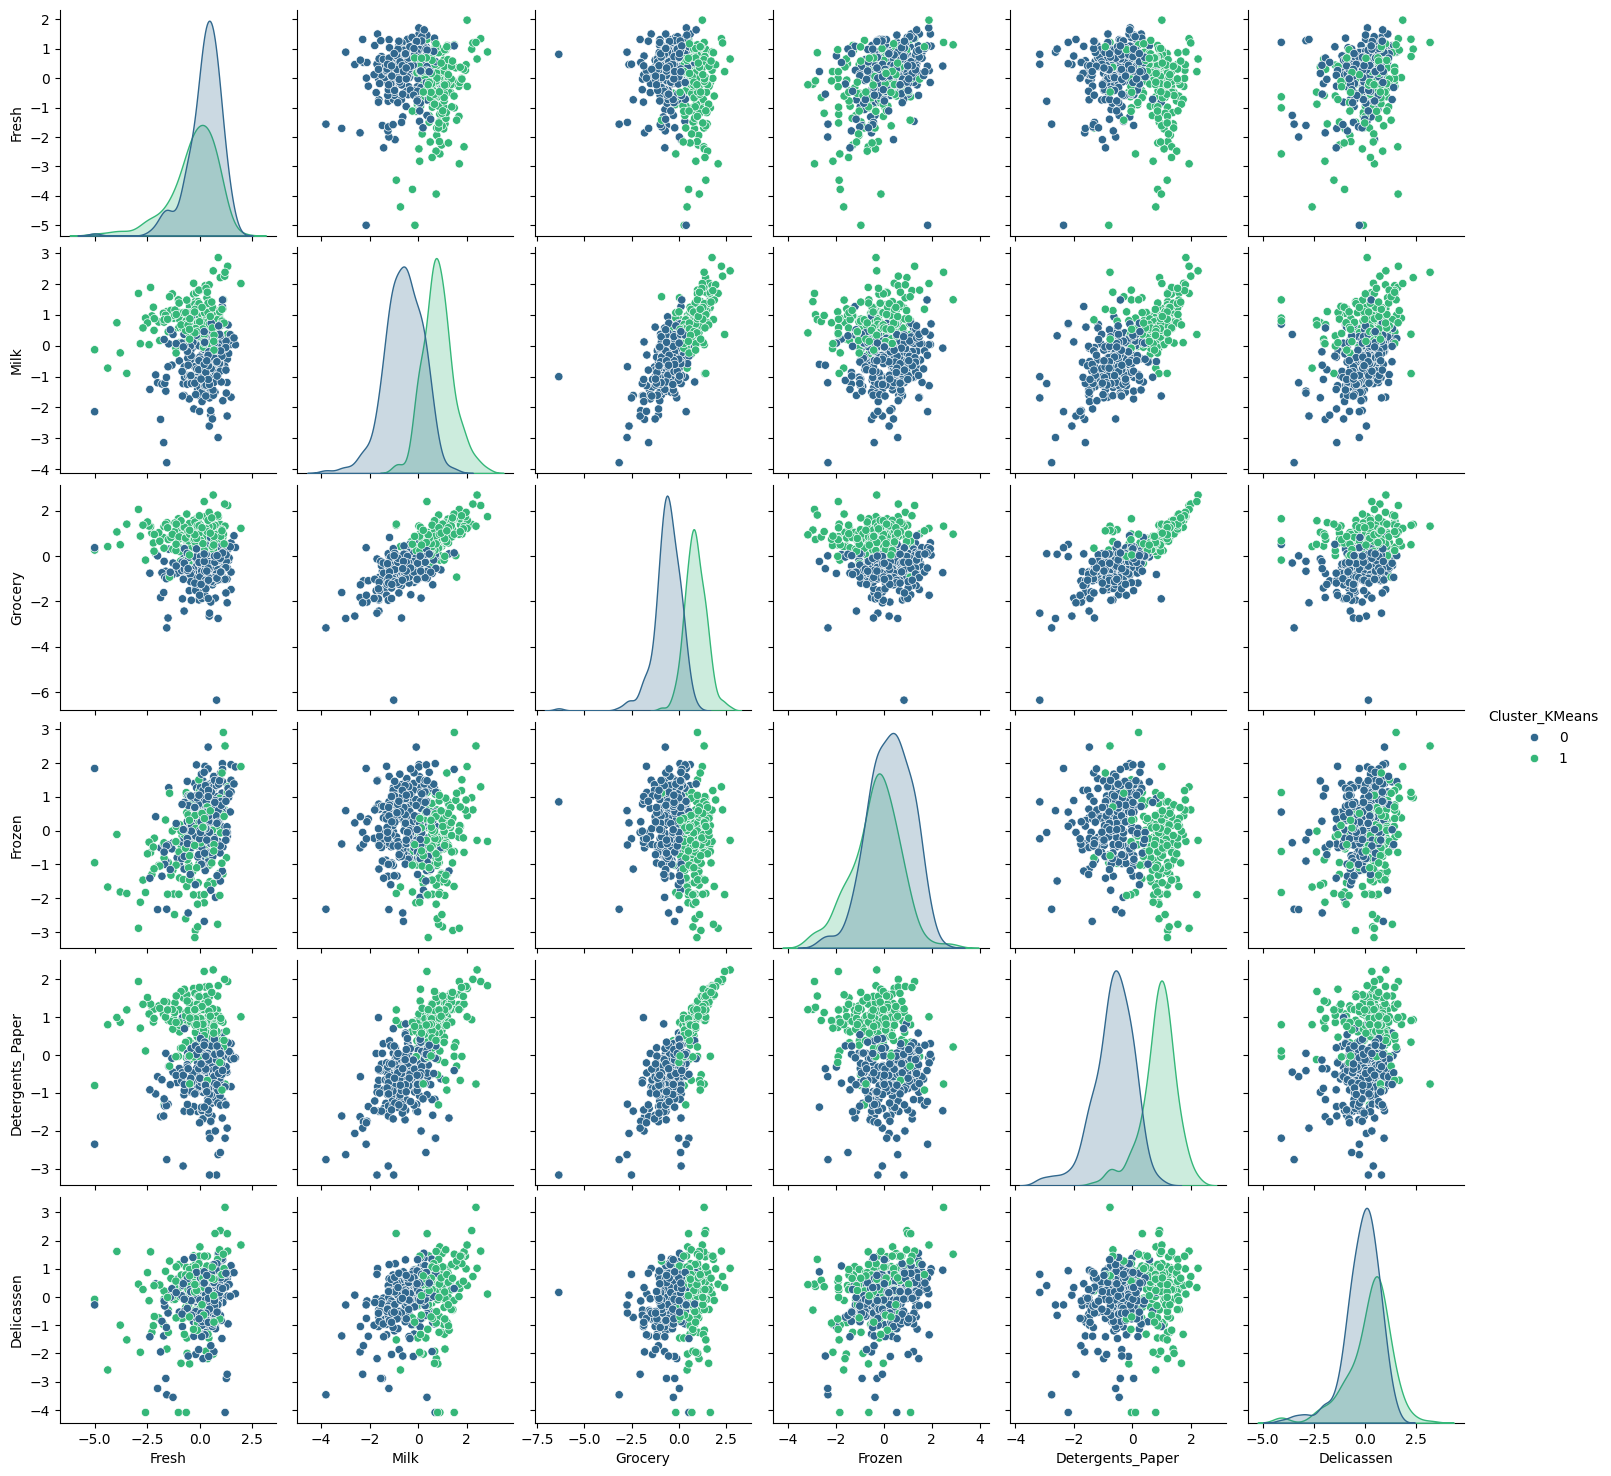

In [20]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=X_scaled_df,
    x='Fresh',
    y='Milk',
    hue='Cluster_KMeans',
    palette='viridis',
    s=70
)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

plot_pairs = [
    ('Grocery', 'Detergents_Paper'),
    ('Milk', 'Detergents_Paper'),
    ('Milk', 'Delicassen'),
    ('Frozen', 'Delicassen')
]

for ax, (x_feature, y_feature) in zip(axes.ravel(), plot_pairs):
    sns.scatterplot(
        data=X_scaled_df,
        x=x_feature,
        y=y_feature,
        hue='Cluster_KMeans',
        palette='viridis',
        s=60,
        ax=ax
    )
    ax.set_title(f'{x_feature} vs {y_feature}')
    ax.set_xlabel(f'{x_feature} (scaled)')
    ax.set_ylabel(f'{y_feature} (scaled)')
    ax.legend(title='Cluster')

plt.suptitle('Visualisasi Cluster K-Means Berdasarkan Korelasi', fontsize=16)
plt.tight_layout()

sns.pairplot(
    data=X_scaled_df,
    vars=continuous_features,
    hue='Cluster_KMeans',
    palette='viridis',
    diag_kind='kde',
)

plt.show()

## 11. Profil dan Interpretasi Cluster K-Means

Hitung nilai rata-rata fitur pada setiap cluster.

**Buat tabel profil cluster dan berikan deskripsi singkat karakteristik masing-masing cluster.**


In [21]:
# rata-rata pengeluaran tiap cluster
cluster_profile = (
    df[continuous_features]
    .assign(Cluster=labels_kmeans)
    .groupby('Cluster')
    .mean()
    .round(2)
)

cluster_profile['Jumlah Anggota'] = (
    pd.Series(labels_kmeans)
    .value_counts()
    .sort_index()
)

display(cluster_profile)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Jumlah Anggota
Cluster,,,,,,,
0,13973.13,2401.75,2918.71,3705.67,491.94,1038.04,252
1,9355.87,10346.36,14697.06,2222.45,6084.51,2177.43,188


Berdasarkan tabel profil, Cluster 0 dan Cluster 1 memiliki pola pengeluaran yang berbeda. Cluster dengan nilai rata-rata pengeluaran lebih tinggi pada sebagian besar kategori dapat dikategorikan sebagai pelanggan dengan tingkat pengeluaran tinggi. Sementara itu, cluster dengan nilai rata-rata lebih rendah dapat dikategorikan sebagai pelanggan dengan tingkat pengeluaran menegah kebawah.

In [22]:
cluster_profile['Total Pengeluaran'] = (
    cluster_profile[continuous_features].sum(axis=1).round(2)
)

display(cluster_profile)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Jumlah Anggota,Total Pengeluaran
Cluster,,,,,,,,
0,13973.13,2401.75,2918.71,3705.67,491.94,1038.04,252,24529.24
1,9355.87,10346.36,14697.06,2222.45,6084.51,2177.43,188,44883.68


### Pertanyaan Analisis K-Means

**1.** Berdasarkan Elbow Method dan Silhouette Score, berapa jumlah cluster yang digunakan? Jelaskan dasar pemilihannya.

**2.** Bagaimana karakteristik utama dari setiap cluster berdasarkan pola pengeluaran pelanggan?

**Jawaban:**


1. Berdasarkan elbow method cluster yang dipilih adalah 2 karena kurva mulai melandai dari titik tersebut, sudut kurva paling tajam terjadi di titk 2, kemudian dilanjutkan tren yang melandai relatif stabil, menunjukkan bahwa menambahkan lebih banyak cluster tidak mengurangi inertia secara signifikan. Dilanjutkan dengan silhoutte silhoutte score yang menghasilkan skor 2.8 sampai dengan 2.9 dimana merupakan skor tertinggi dari beberapa percoban menambah lebih banyak cluster, sehingga jumlah cluster yang digunakan adalah 2.

2. Berdasarkan tabel profil, Cluster 0 dan Cluster 1 memiliki pola pengeluaran yang berbeda. Cluster dengan nilai rata-rata pengeluaran lebih tinggi pada sebagian besar kategori dapat dikategorikan sebagai pelanggan dengan tingkat pengeluaran tinggi. Sementara itu, cluster dengan nilai rata-rata lebih rendah dapat dikategorikan sebagai pelanggan dengan tingkat pengeluaran menegah kebawah.

# B. HIERARCHICAL CLUSTERING

Gunakan **dataset dan hasil preprocessing/scaling yang sama** seperti pada K-Means.


## 12. Agglomerative Clustering dengan Beberapa Linkage

Coba beberapa linkage yang telah dipelajari:
- Ward
- Average
- Complete
- Single

Gunakan jumlah cluster yang sama terlebih dahulu untuk melakukan perbandingan linkage.


In [23]:
model_ward = AgglomerativeClustering(n_clusters=2, linkage='ward')
labels_ward = model_ward.fit_predict(X_scaled_df)
print(labels_ward[:10])

model_complete = AgglomerativeClustering(n_clusters=2, linkage='complete')
labels_complete = model_complete.fit_predict(X_scaled_df)
print(labels_complete[:10])

model_average = AgglomerativeClustering(n_clusters=2, linkage='average')
labels_average = model_average.fit_predict(X_scaled_df)
print(labels_average[:10])

model_single = AgglomerativeClustering(n_clusters=2, linkage='single')
labels_single = model_single.fit_predict(X_scaled_df)
print(labels_single[:10])

[0 0 0 1 0 0 0 0 0 0]
[1 1 1 1 1 1 1 1 1 1]
[1 1 1 1 1 1 1 1 1 1]
[0 0 0 0 0 0 0 0 0 0]


## 13. Perbandingan Silhouette Score

Hitung dan tampilkan Silhouette Score untuk:
- Ward
- Average
- Complete
- Single

Buat tabel perbandingan agar hasil mudah dibaca.


In [24]:
for linkage_method, labels in {
    'ward': labels_ward,
    'complete': labels_complete,
    'average': labels_average,
    'single': labels_single
}.items():
    silhouette_avg = silhouette_score(X_scaled_df[continuous_features], labels)
    print(f"Silhouette Score for Agglomerative Clustering with {linkage_method} linkage: {silhouette_avg:.4f}")


Silhouette Score for Agglomerative Clustering with ward linkage: 0.2883
Silhouette Score for Agglomerative Clustering with complete linkage: 0.3373
Silhouette Score for Agglomerative Clustering with average linkage: 0.5691
Silhouette Score for Agglomerative Clustering with single linkage: 0.5700


## 14. Dendrogram – Ward

Buat dendrogram menggunakan linkage **Ward**.

Gunakan dendrogram untuk menentukan jumlah cluster yang wajar berdasarkan struktur penggabungan cluster.


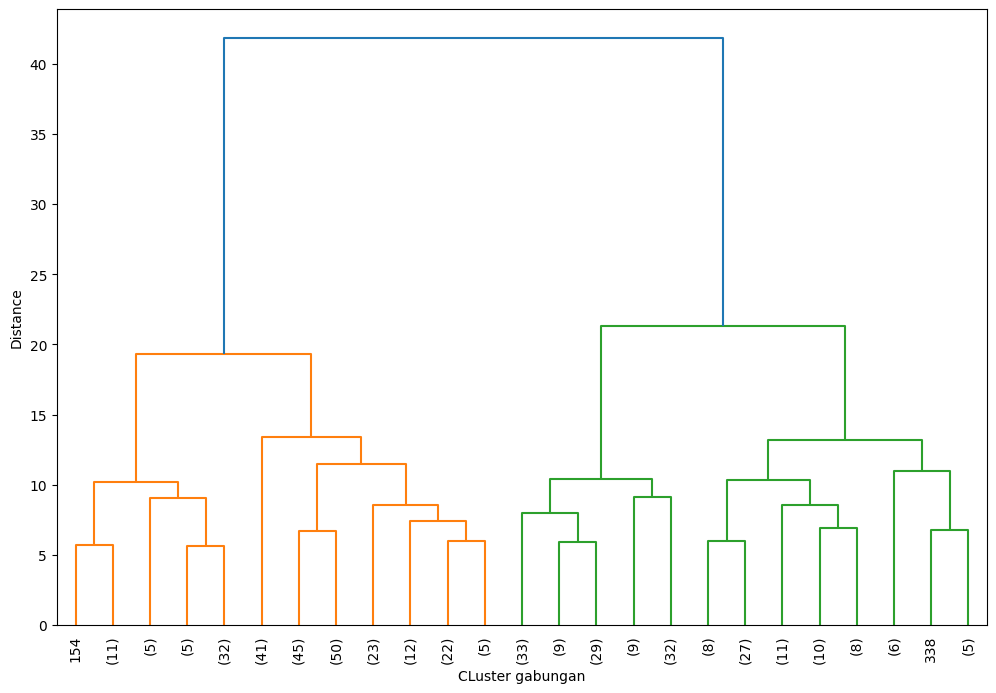

In [25]:
Z = linkage(X_scaled_df, method='ward')
plt.figure(figsize=(12, 8))
dendrogram(Z, leaf_rotation=90, truncate_mode='lastp', p=25, leaf_font_size=10)
plt.xlabel("CLuster gabungan")
plt.ylabel("Distance")
plt.show()


## 15. Menentukan Jumlah Cluster dari Dendrogram

Tuliskan:
- ketinggian pemotongan yang digunakan (jika digunakan);
- jumlah cluster yang diperoleh;
- alasan pemilihan jumlah cluster.


Ketinggian merge untuk membentuk k_target=2 klaster: 21.3175
Ketinggian merge berikutnya: 41.7861
Maksimum jarak merge: 31.5518


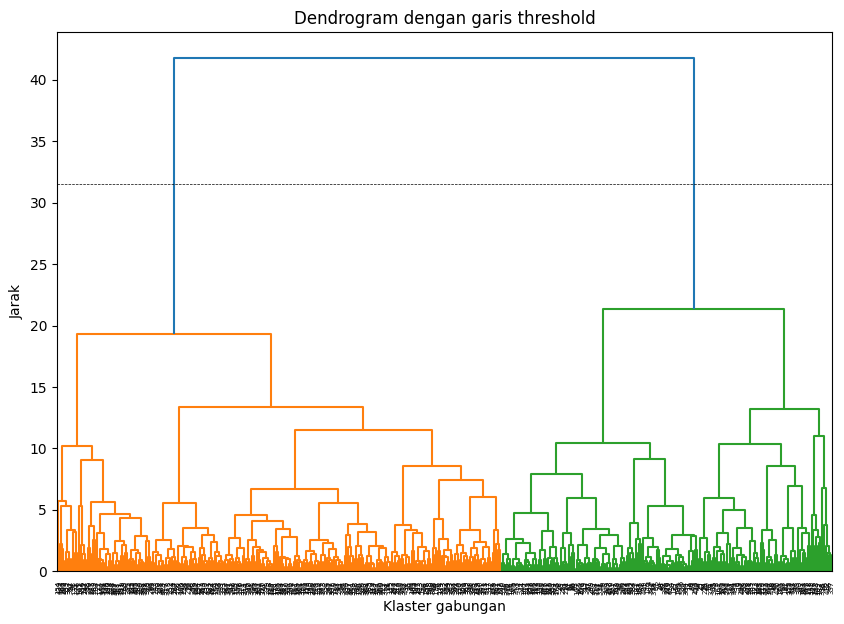

In [26]:
k_target = 2
n = X_scaled.shape[0]
idx_masuk_k = n - k_target - 1
idx_keluar_k = idx_masuk_k + 1
max_d = (Z[idx_masuk_k, 2] + Z[idx_keluar_k, 2]) / 2
print(f'Ketinggian merge untuk membentuk k_target={k_target} klaster: {Z[idx_masuk_k, 2]:.4f}')
print(f'Ketinggian merge berikutnya: {Z[idx_keluar_k, 2]:.4f}')
print(f'Maksimum jarak merge: {max_d:.4f}')

plt.figure(figsize=(10, 7))
dendrogram(Z, show_leaf_counts=True, color_threshold=max_d)
plt.axhline(y=max_d, c='k', ls='--', lw=0.5)
plt.xlabel('Klaster gabungan')
plt.ylabel('Jarak')
plt.title('Dendrogram dengan garis threshold')
plt.show()

Berdasarkan dendrogram Ward, jumlah cluster yang dipilih adalah 2 cluster. Pemotongan dendrogram dilakukan pada ketinggian max_d yang berada di antara dua penggabungan terakhir. Pada ketinggian tersebut terbentuk dua kelompok pelanggan, sedangkan jika garis pemotongan dinaikkan melewati penggabungan terakhir, seluruh data akan menjadi satu cluster.

Jumlah cluster 2 dipilih karena terdapat jarak penggabungan yang cukup besar sebelum dua cluster terakhir digabungkan. Hal ini menunjukkan bahwa dua cluster tersebut memiliki karakteristik pengeluaran yang relatif berbeda.

## 16. Heatmap Cluster

Buat heatmap fitur yang telah distandarisasi dan diurutkan berdasarkan label cluster.

Gunakan heatmap untuk membantu melihat fitur yang membedakan karakteristik antar-cluster.


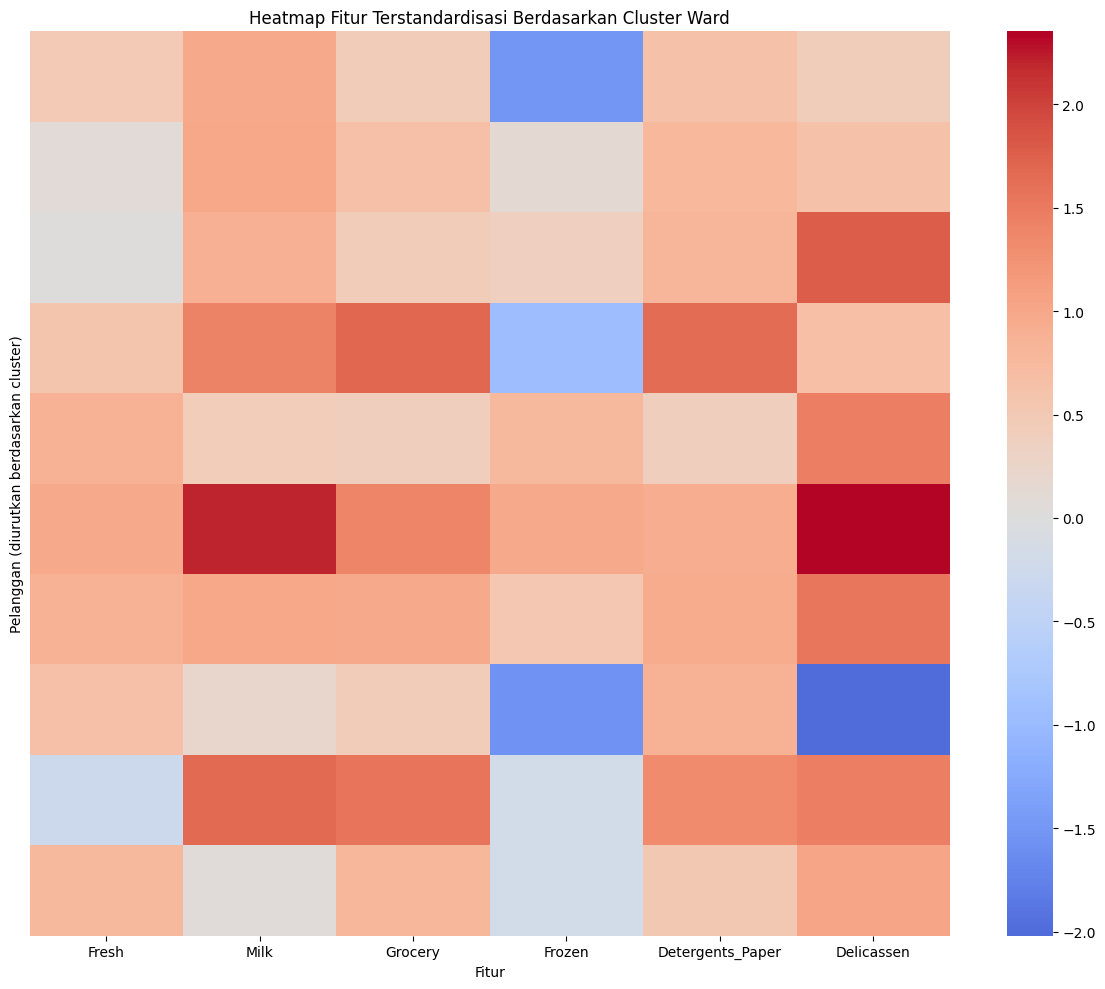

In [27]:
heatmap_data = X_scaled_df[continuous_features].copy()
heatmap_data['Cluster'] = labels_ward

heatmap_data = heatmap_data.sort_values('Cluster')
heatmap_features = heatmap_data[continuous_features][:10]

plt.figure(figsize=(12, 10))

sns.heatmap(
    heatmap_features,
    cmap='coolwarm',
    center=0,
    yticklabels=False,
    xticklabels=continuous_features
)

plt.title('Heatmap Fitur Terstandardisasi Berdasarkan Cluster Ward')
plt.xlabel('Fitur')
plt.ylabel('Pelanggan (diurutkan berdasarkan cluster)')
plt.tight_layout()
plt.show()

## 17. Profil dan Interpretasi Cluster Hierarchical

Buat tabel profil cluster berdasarkan nilai rata-rata fitur.

Jelaskan karakteristik masing-masing cluster.


In [28]:
# rata-rata pengeluaran tiap cluster Hierarchical
hierarchical_profile = (
    df[continuous_features]
    .assign(Cluster=labels_ward)
    .groupby('Cluster')
    .mean()
    .round(2)
)

hierarchical_profile['Jumlah Anggota'] = (
    pd.Series(labels_ward)
    .value_counts()
    .sort_index()
)

# menghitung total rata-rata pengeluaran
hierarchical_profile['Total Pengeluaran'] = (
    hierarchical_profile[continuous_features]
    .sum(axis=1)
    .round(2)
)

display(hierarchical_profile)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Jumlah Anggota,Total Pengeluaran
Cluster,,,,,,,,
0,9404.76,10216.25,14741.39,2261.93,6076.46,2140.60,188,44841.39
1,13936.65,2498.82,2885.64,3676.22,497.94,1065.52,252,24560.79


### Pertanyaan Analisis Hierarchical

**1.** Linkage mana yang menghasilkan Silhouette Score paling tinggi? Jelaskan apa yang dapat ditunjukkan oleh hasil tersebut.

**2.** Berdasarkan dendrogram Ward, berapa jumlah cluster yang menurutmu paling wajar? Jelaskan dasar pemilihannya.

**Jawaban:**


1. Linkage yang menghasilkan Silhouette Score paling tinggi adalah linkage dengan nilai skor terbesar pada tabel perbandingan. Linkage tersebut menghasilkan pembagian cluster yang paling baik dibandingkan linkage lainnya karena anggota dalam cluster relatif lebih mirip, sedangkan jarak antar-cluster relatif lebih besar. Nilai Silhouette Score yang tidak terlalu tinggi menunjukkan bahwa sebagian data pelanggan masih memiliki karakteristik yang saling tumpang tindih.

2. Berdasarkan dendrogram Ward, jumlah cluster yang paling wajar adalah **2 cluster**. Pemotongan dendrogram dilakukan pada ketinggian `max_d`, yaitu di antara dua penggabungan terakhir. Pada ketinggian tersebut terbentuk dua kelompok pelanggan. Pemilihan 2 cluster juga didukung oleh adanya jarak penggabungan yang cukup besar sebelum kedua cluster terakhir digabungkan, sehingga kedua kelompok tersebut memiliki karakteristik pengeluaran yang relatif berbeda.

# C. PERBANDINGAN K-MEANS DAN HIERARCHICAL

Kedua algoritma diterapkan pada dataset dan hasil preprocessing yang sama.

## 18. Perbandingan Hasil

Bandingkan hasil K-Means dan Hierarchical berdasarkan:
- jumlah cluster;
- pembagian data;
- Silhouette Score;
- karakteristik cluster.


In [29]:
silhouette_kmeans = silhouette_score(
    X_scaled_df[continuous_features],
    labels_kmeans
)

silhouette_ward = silhouette_score(
    X_scaled_df[continuous_features],
    labels_ward
)

comparison_table = pd.DataFrame({
    'Metode': ['K-Means', 'Hierarchical Ward'],
    'Jumlah Cluster': [len(np.unique(labels_kmeans)), len(np.unique(labels_ward))],
    'Silhouette Score': [silhouette_kmeans, silhouette_ward],
    'Jumlah Anggota Cluster 0': [
        np.sum(labels_kmeans == 0),
        np.sum(labels_ward == 0)
    ],
    'Jumlah Anggota Cluster 1': [
        np.sum(labels_kmeans == 1),
        np.sum(labels_ward == 1)
    ]
})

comparison_table['Silhouette Score'] = (
    comparison_table['Silhouette Score'].round(4)
)

display(comparison_table)

,Metode,Jumlah Cluster,Silhouette Score,Jumlah Anggota Cluster 0,Jumlah Anggota Cluster 1
0,K-Means,2,0.2903,252,188
1,Hierarchical Ward,2,0.2883,188,252


### Pertanyaan Analisis Perbandingan

**1.** Apa perbedaan utama hasil K-Means dan Hierarchical Clustering pada dataset yang sama? Jelaskan berdasarkan jumlah cluster, pembagian data, atau karakteristik cluster yang terbentuk.

**Jawaban:**


K-Means dan Hierarchical Clustering sama-sama menggunakan enam fitur pengeluaran yang telah ditransformasi dan distandardisasi, yaitu `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, dan `Delicassen`. Kedua metode juga menggunakan jumlah cluster yang sama, yaitu 2 cluster.

Perbedaan utama terletak pada cara pembentukan cluster. K-Means membentuk cluster berdasarkan jarak setiap data terhadap centroid, sedangkan Hierarchical Clustering membentuk cluster secara bertahap berdasarkan penggabungan data atau kelompok data yang memiliki kemiripan. Jumlah anggota dan pembagian pelanggan pada kedua metode dapat berbeda. Perbedaan tersebut terjadi karena setiap algoritma menggunakan pendekatan yang berbeda. Karakteristik cluster dibandingkan melalui rata-rata pengeluaran setiap kategori. Cluster dengan rata-rata pengeluaran lebih tinggi menunjukkan pelanggan dengan pengeluaran tinggi, sedangkan cluster dengan rata-rata lebih rendah menunjukkan pelanggan dengan pengeluaran rendah. Metode dengan Silhouette Score lebih tinggi menghasilkan pemisahan cluster yang lebih baik pada dataset ini.

# D. KESIMPULAN

Tuliskan kesimpulan singkat berdasarkan:
1. hasil K-Means;
2. hasil Hierarchical Clustering;
3. perbedaan hasil kedua metode.


Berdasarkan hasil analisis, K-Means dan Hierarchical Clustering berhasil mengelompokkan pelanggan berdasarkan pola pengeluaran pada enam kategori produk, yaitu `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, dan `Delicassen`. Data terlebih dahulu ditransformasi menggunakan logaritma dan distandardisasi agar pengaruh skewness serta perbedaan skala fitur dapat dikurangi.

1. Pada K-Means, jumlah cluster yang digunakan adalah 2. Pemilihan ini didasarkan pada grafik Elbow yang mulai melandai setelah k = 2 serta hasil Silhouette Score. Cluster yang terbentuk menunjukkan perbedaan tingkat pengeluaran pelanggan, yaitu kelompok dengan pengeluaran relatif rendah dan kelompok dengan pengeluaran relatif tinggi.

2. Pada Hierarchical Clustering, metode Agglomerative dengan beberapa linkage dibandingkan menggunakan Silhouette Score. Linkage dengan nilai Silhouette Score tertinggi dianggap menghasilkan pembagian cluster terbaik. Berdasarkan dendrogram Ward, jumlah cluster yang paling wajar adalah 2 karena terdapat jarak penggabungan yang cukup besar sebelum dua cluster terakhir digabungkan.

3. Perbedaan K-Means dan Hierarchical Clustering terletak pada cara pembentukan cluster. K-Means menggunakan centroid, sedangkan Hierarchical Clustering membentuk kelompok secara bertahap berdasarkan kemiripan antar-data. Akibatnya, jumlah anggota dan pembagian pelanggan dapat berbeda meskipun menggunakan dataset, preprocessing, dan jumlah cluster yang sama. Secara keseluruhan, kedua metode dapat digunakan untuk membantu segmentasi pelanggan berdasarkan pola pengeluaran.